# Mini Project 9 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_09.py` (bagian wajib) dan `features/mp09_extension_dataset_audit.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 9 — Membangun Dataset dan Membekukan Split Eksperimen
Enam acquisition block × empat perintah (nyala, mati, naik, turun) = 24 WAV.
Filter final MP6 + preprocessing MP7 + feature schema MP8 diterapkan otomatis,
metadata & log-Mel disimpan, lalu grouped split (block 1–4 train, 5 validation,
6 test) dibekukan untuk MP10–MP13. Status -> `ready_for_mp10`.

**Mode akuisisi** (`ACQUISITION_MODE`, dapat dioverride env `MP09_MODE`):
* `mic`  : rekam langsung dari mikrofon (prosedur buku, DEMO_MODE=False).
* `tts`  : *speech synthesis* Windows SAPI (2 suara) + simulasi variasi kanal per block
           (posisi mic → gain, reverb, noise floor, hum). Dipakai pada pengerjaan ini karena
           sesi pengerjaan tidak memiliki akses mikrofon; label & grouping tetap sesuai protokol.
* `demo` : sinyal sintetis sinus dari buku (hanya untuk tes skrip).

WAV yang sudah ada **tidak direkam ulang**. Untuk mengganti dataset dengan rekaman suara
kelompok: hapus `data/raw/mp09_dataset/*.wav`, set `MP09_MODE=mic`, jalankan ulang skrip ini,
lalu jalankan `python ../run_all_mini_projects.py --start 10`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import csv, json, time, os, subprocess, tempfile
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import lfilter, resample_poly, fftconvolve
from scipy.fft import dct

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
STATUS = ROOT / 'project_status.json'
DEMO_MODE = False       # True hanya untuk pengujian tanpa mikrofon (sinyal sinus buku)
ACQUISITION_MODE = os.environ.get('MP09_MODE', 'demo' if DEMO_MODE else 'tts')  # 'mic' | 'tts' | 'demo'
N_BLOCKS = 6
DURATION_S = 1.2
SEED = 2026
rng = np.random.default_rng(SEED)

## Langkah 1 — Validasi status MP8 dan muat konfigurasi yang sudah dikunci

In [2]:
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp09', 'ready_for_mp10'), status['status']

project_cfg = json.loads((ROOT/'config/project_config.json').read_text(encoding='utf-8'))
pre_cfg = json.loads((ROOT/'config/preprocessing_config.json').read_text(encoding='utf-8'))
feat_cfg = json.loads((ROOT/'config/feature_config.json').read_text(encoding='utf-8'))
filter_npz = np.load(ROOT/'features/intermediate/mp06_filter_final.npz', allow_pickle=True)

FS = int(project_cfg.get('sampling_rate_hz', project_cfg.get('sample_rate_hz', 16000)))
LABELS = project_cfg.get('labels', ['nyala', 'mati', 'naik', 'turun'])
B = np.asarray(filter_npz['b'], dtype=float)
A = np.asarray(filter_npz['a'], dtype=float)
N = int(pre_cfg['frame_length_samples'])
H = int(pre_cfg['hop_length_samples'])
TARGET_PEAK = float(pre_cfg['normalization']['target_peak'])
PREEMPH = float(pre_cfg['pre_emphasis_alpha'])
N_MELS = int(feat_cfg['mel']['n_mels'])
N_MFCC = int(feat_cfg['mfcc']['n_mfcc'])
FMIN = float(feat_cfg['mel']['fmin_hz'])
FMAX = float(feat_cfg['mel']['fmax_hz'])

raw_dir = ROOT/'data/raw/mp09_dataset'
meta_dir = ROOT/'data/metadata'
dataset_dir = ROOT/'features/dataset'
logmel_dir = ROOT/'features/logmel/mp09'
split_dir = ROOT/'splits'
metric_dir = ROOT/'results/metrics'
fig_dir = ROOT/'results/figures'
for d in [raw_dir, meta_dir, dataset_dir, logmel_dir, split_dir, metric_dir, fig_dir]:
    d.mkdir(parents=True, exist_ok=True)
print('Acquisition mode:', ACQUISITION_MODE, '| fs =', FS, '| labels =', LABELS)

Acquisition mode: tts | fs = 16000 | labels = ['nyala', 'mati', 'naik', 'turun']


## Akuisisi: mic (buku), TTS + simulasi kanal per block, atau demo sintetis
Protokol per block pada mode `tts` meniru instruksi buku "ubah posisi mikrofon sedikit
antar block": tiap block memiliki suara, laju bicara, jarak (gain), reverb, noise floor,
dan hum yang berbeda — sehingga block menjadi unit grouping yang bermakna.

In [3]:
# Ejaan fonetik agar suara TTS berbahasa Inggris melafalkan kata Indonesia mendekati aslinya
TTS_TEXT = {'nyala': 'nyah lah', 'mati': 'mah tee', 'naik': 'nah eek', 'turun': 'too roon'}
BLOCK_PROFILE = {
    # block: voice, SAPI rate, speed factor, gain dB (jarak), SNR dB, RT60 s, hum amplitude
    1: dict(voice='Microsoft Zira Desktop',  rate=0,  speed=1.00, gain_db=0.0,  snr_db=34, rt60=0.15, hum=0.003),
    2: dict(voice='Microsoft David Desktop', rate=0,  speed=1.00, gain_db=-3.0, snr_db=32, rt60=0.20, hum=0.004),
    3: dict(voice='Microsoft Zira Desktop',  rate=-2, speed=0.95, gain_db=-6.0, snr_db=29, rt60=0.26, hum=0.005),
    4: dict(voice='Microsoft David Desktop', rate=2,  speed=1.05, gain_db=-2.0, snr_db=30, rt60=0.18, hum=0.003),
    5: dict(voice='Microsoft Zira Desktop',  rate=1,  speed=1.03, gain_db=-4.0, snr_db=30, rt60=0.22, hum=0.004),
    6: dict(voice='Microsoft David Desktop', rate=-1, speed=0.97, gain_db=-5.0, snr_db=29, rt60=0.24, hum=0.005),
}


def save_wav(path, y):
    y = np.clip(y, -1, 1)
    wavfile.write(path, FS, np.round(y*32767).astype(np.int16))


def _tts_render(jobs):
    """Render banyak ucapan sekaligus via Windows SAPI (System.Speech) ke WAV 16 kHz mono 16-bit."""
    lines = ["Add-Type -AssemblyName System.Speech",
             "$fmt = New-Object System.Speech.AudioFormat.SpeechAudioFormatInfo(16000, [System.Speech.AudioFormat.AudioBitsPerSample]::Sixteen, [System.Speech.AudioFormat.AudioChannel]::Mono)"]
    for text, voice, rate, out in jobs:
        lines += ["$s = New-Object System.Speech.Synthesis.SpeechSynthesizer",
                  f"$s.SelectVoice('{voice}')", f"$s.Rate = {int(rate)}",
                  f"$s.SetOutputToWaveFile('{out}', $fmt)", f"$s.Speak('{text}')", "$s.Dispose()"]
    with tempfile.NamedTemporaryFile('w', suffix='.ps1', delete=False, encoding='utf-8') as f:
        f.write("\n".join(lines)); ps1 = f.name
    try:
        subprocess.run(['powershell', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File', ps1],
                       check=True, capture_output=True, timeout=300)
    finally:
        os.unlink(ps1)


def _synthetic_rir(rt60, block):
    r = np.random.default_rng(SEED + 100*block)
    n = int(0.3*FS); t = np.arange(n)/FS
    h = r.normal(size=n)*np.exp(-6.9*t/rt60)*0.25
    h[:int(0.002*FS)] = 0; h[0] = 1.0
    for d_ms, g in [(7 + 2*block, 0.35), (19 + block, -0.2)]:
        h[int(d_ms*FS/1000)] += g
    return h/np.sqrt(np.sum(h**2))


def _apply_channel(speech, block, label):
    """Simulasi posisi mikrofon per block: speed perturbation, reverb, gain, noise floor, hum, onset acak."""
    p = BLOCK_PROFILE[block]
    r = np.random.default_rng(SEED + 1000*block + LABELS.index(label))
    sp = speech/(np.max(np.abs(speech))+1e-12)
    # trim diam bawaan TTS
    env = np.abs(sp) > 0.02
    if env.any():
        i0, i1 = np.argmax(env), len(env)-np.argmax(env[::-1])
        sp = sp[max(0, i0-80):i1+80]
    speed = p['speed']*r.uniform(0.98, 1.02)
    up, down = int(round(1000/speed)), 1000
    sp = resample_poly(sp, up, down)
    sp = fftconvolve(sp, _synthetic_rir(p['rt60'], block))[:len(sp)+int(0.12*FS)]
    sp = 0.5*sp/(np.max(np.abs(sp))+1e-12)*10**(p['gain_db']/20)
    n_total = int(DURATION_S*FS)
    sp = sp[:n_total-int(0.05*FS)]
    onset = int(r.uniform(0.10, max(0.11, (n_total-len(sp))/FS-0.05))*FS)
    y = np.zeros(n_total); y[onset:onset+len(sp)] += sp
    # noise floor (pink-ish) pada SNR target relatif terhadap daya ucapan aktif
    wn = r.normal(size=n_total); pink = lfilter([0.049922035, -0.095993537, 0.050612699, -0.004408786],
                                               [1, -2.494956002, 2.017265875, -0.522189400], wn)
    p_sp = np.mean(sp**2)
    pink *= np.sqrt(p_sp/(np.mean(pink**2)*10**(p['snr_db']/10)))
    t = np.arange(n_total)/FS
    y += pink + p['hum']*np.sin(2*np.pi*50*t + r.uniform(0, 2*np.pi))
    return y


_TTS_CACHE = {}


def acquire(label, block):
    path = raw_dir/f'{label}_b{block:02d}.wav'
    if path.exists():
        return path
    if ACQUISITION_MODE == 'demo':
        # synthetic fallback hanya untuk test script
        f0 = {'nyala': 170, 'mati': 205, 'naik': 240, 'turun': 145}[label]
        t = np.arange(int(DURATION_S*FS))/FS
        env = np.sin(np.pi*np.clip(t/DURATION_S, 0, 1))**1.4
        y = env*(0.45*np.sin(2*np.pi*f0*t)+0.16*np.sin(2*np.pi*2.3*f0*t))
        y += 0.012*rng.normal(size=len(t)) + 0.006*(block-1)*np.sin(2*np.pi*50*t)
    elif ACQUISITION_MODE == 'tts':
        if not _TTS_CACHE:
            tmp = Path(tempfile.mkdtemp(prefix='mp09_tts_'))
            jobs = []
            for b_, prof in BLOCK_PROFILE.items():
                for lab in LABELS:
                    out = tmp/f'{lab}_b{b_:02d}.wav'
                    jobs.append((TTS_TEXT[lab], prof['voice'], prof['rate'], str(out)))
            _tts_render(jobs)
            for b_ in BLOCK_PROFILE:
                for lab in LABELS:
                    fs_t, s = wavfile.read(tmp/f'{lab}_b{b_:02d}.wav')
                    assert fs_t == FS
                    _TTS_CACHE[(lab, b_)] = s.astype(np.float64)/32768.0
        y = _apply_channel(_TTS_CACHE[(label, block)], block, label)
    else:
        import sounddevice as sd
        input(f'Block {block} | ucapkan "{label}" lalu tekan ENTER... ')
        print('Merekam...')
        y = sd.rec(int(DURATION_S*FS), samplerate=FS, channels=1, dtype='float32')
        sd.wait(); y = y[:, 0]
    save_wav(path, y)
    return path

## Front-end beku MP6 + MP7 + MP8 (filter → preprocessing → 39-D + log-Mel)

In [4]:
def read_float(path):
    fs, y = wavfile.read(path)
    assert fs == FS, (path, fs)
    if y.ndim > 1: y = y.mean(axis=1)
    if np.issubdtype(y.dtype, np.integer): y = y.astype(np.float64)/np.iinfo(y.dtype).max
    else: y = y.astype(np.float64)
    return y


def hz_to_mel(f): return 2595*np.log10(1+np.asarray(f)/700.0)
def mel_to_hz(m): return 700*(10**(np.asarray(m)/2595.0)-1)


def melbank(n_fft):
    m = np.linspace(hz_to_mel(FMIN), hz_to_mel(FMAX), N_MELS+2)
    hz = mel_to_hz(m); bins = np.floor((n_fft+1)*hz/FS).astype(int)
    fb = np.zeros((N_MELS, n_fft//2+1))
    for i in range(1, N_MELS+1):
        l, c, r = bins[i-1], bins[i], bins[i+1]; c = max(c, l+1); r = max(r, c+1)
        for k in range(l, min(c, fb.shape[1])): fb[i-1, k] = (k-l)/(c-l)
        for k in range(c, min(r, fb.shape[1])): fb[i-1, k] = (r-k)/(r-c)
    return fb


FB = melbank(N)
FREQ = np.fft.rfftfreq(N, 1/FS)


def preprocess(y):
    # filter final MP6
    y = lfilter(B, A, y)
    y = y-np.mean(y)
    pk = np.max(np.abs(y))+1e-12; y = y*(TARGET_PEAK/pk)
    if len(y) < N: y = np.pad(y, (0, N-len(y)))
    starts = np.arange(0, len(y)-N+1, H)
    raw = np.array([y[s:s+N] for s in starts])
    rms = np.sqrt(np.mean(raw**2, axis=1)+1e-12)
    thr = float(pre_cfg['vad']['relative_factor'])*np.max(rms)
    active = np.where(rms >= thr)[0]
    if len(active):
        margin = int(pre_cfg['vad'].get('margin_frames', 2))
        i0 = max(0, int(active[0])-margin); i1 = min(len(raw)-1, int(active[-1])+margin)
        y = y[starts[i0]:min(len(y), starts[i1]+N)]
    # denoise tidak dipaksakan bila MP7 menandai noise estimate tidak reliable
    if len(y) < N: y = np.pad(y, (0, N-len(y)))
    starts = np.arange(0, len(y)-N+1, H)
    fr = np.array([y[s:s+N] for s in starts])
    fr = np.concatenate([fr[:, :1], fr[:, 1:]-PREEMPH*fr[:, :-1]], axis=1)
    return fr*np.hamming(N)[None, :]


def pitch_one(frame):
    x = frame-np.mean(frame); ac = np.correlate(x, x, mode='full')[len(x)-1:]
    if ac[0] <= 1e-12: return 0.0, 0.0
    ac = ac/(ac[0]+1e-12)
    lo = max(1, int(FS/feat_cfg['pitch']['max_hz'])); hi = min(len(ac)-1, int(FS/feat_cfg['pitch']['min_hz']))
    if hi <= lo: return 0.0, 0.0
    lag = int(np.argmax(ac[lo:hi+1])+lo); conf = float(ac[lag]); f0 = FS/lag
    if conf < float(feat_cfg['pitch']['confidence_threshold']): return 0.0, conf
    return float(f0), conf


def extract(path):
    y = read_float(path); frames = preprocess(y)
    rms = np.sqrt(np.mean(frames**2, axis=1)+1e-12)
    zcr = np.mean(np.abs(np.diff(np.signbit(frames), axis=1)), axis=1)
    spec = np.abs(np.fft.rfft(frames, axis=1))+1e-12; power = spec**2
    den = np.sum(power, axis=1)+1e-12
    centroid = np.sum(power*FREQ[None, :], axis=1)/den
    bw = np.sqrt(np.sum(power*(FREQ[None, :]-centroid[:, None])**2, axis=1)/den)
    cum = np.cumsum(power, axis=1); total = cum[:, -1]
    roll = np.array([FREQ[min(np.searchsorted(cum[i], .85*total[i]), len(FREQ)-1)] for i in range(len(frames))])
    pitch = np.array([pitch_one(f)[0] for f in frames])
    voiced = pitch > 0
    mel = np.maximum(power@FB.T, 1e-12); logmel = np.log(mel)
    mfcc = dct(logmel, type=2, axis=1, norm='ortho')[:, :N_MFCC]
    vals = []; names = []
    for j in range(N_MFCC):
        vals += [float(np.mean(mfcc[:, j])), float(np.std(mfcc[:, j]))]
        names += [f'mfcc{j+1:02d}_mean', f'mfcc{j+1:02d}_std']
    for name, a in [('rms', rms), ('zcr', zcr), ('centroid_hz', centroid), ('bandwidth_hz', bw), ('rolloff85_hz', roll)]:
        vals += [float(np.mean(a)), float(np.std(a))]; names += [name+'_mean', name+'_std']
    pv = pitch[voiced]
    vals += [float(np.mean(pv)) if len(pv) else 0.0, float(np.std(pv)) if len(pv) else 0.0, float(np.mean(voiced))]
    names += ['f0_hz_mean', 'f0_hz_std', 'voiced_ratio']
    assert len(vals) == 39
    return np.asarray(vals, np.float32), np.asarray(names, dtype=object), logmel.astype(np.float32), len(y)/FS

## 1) Akuisisi 6 block × 4 kelas

In [5]:
records = []
for block in range(1, N_BLOCKS+1):
    print(f'--- Acquisition block {block}/{N_BLOCKS} ---')
    for label in LABELS:
        p = acquire(label, block)
        if ACQUISITION_MODE == 'tts':
            subj = 'tts_' + BLOCK_PROFILE[block]['voice'].split()[1].lower()
            dev, dist = 'sapi_tts_simulated_mic', f"gain{BLOCK_PROFILE[block]['gain_db']:+.0f}dB"
        elif ACQUISITION_MODE == 'demo':
            subj, dev, dist = 'synthetic_demo', 'none', 'normal'
        else:
            subj, dev, dist = 'personal_user', 'local_mic', 'normal'
        records.append({'sample_id': p.stem, 'label': label, 'group_id': f'block_{block:02d}',
                        'subject_id': subj, 'device_id': dev, 'distance_tag': dist,
                        'sample_rate_hz': FS, 'path': p.relative_to(ROOT).as_posix()})
    if ACQUISITION_MODE == 'mic' and block < N_BLOCKS:
        print('Istirahat 5–10 detik / ubah posisi mikrofon sedikit sebelum block berikutnya.')
        time.sleep(2)

--- Acquisition block 1/6 ---
--- Acquisition block 2/6 ---
--- Acquisition block 3/6 ---
--- Acquisition block 4/6 ---
--- Acquisition block 5/6 ---
--- Acquisition block 6/6 ---


## 2) Ekstraksi feature schema MP8 untuk seluruh sampel + simpan log-Mel

In [6]:
X = []; y = []; groups = []; ids = []; paths = []; durations = []; feature_names = None
for r in records:
    vec, names, logmel, dur = extract(ROOT/r['path'])
    if feature_names is None: feature_names = names
    else: assert np.array_equal(feature_names, names)
    X.append(vec); y.append(r['label']); groups.append(r['group_id']); ids.append(r['sample_id']); paths.append(r['path']); durations.append(dur)
    np.savez_compressed(logmel_dir/f"{r['sample_id']}.npz", log_mel=logmel, sample_id=r['sample_id'], label=r['label'])
    r['duration_s'] = round(dur, 4)                                   # durasi rekaman mentah (kode buku)
    r['active_duration_s'] = round(((logmel.shape[0]-1)*H + N)/FS, 4)   # durasi setelah VAD trim

X = np.vstack(X); y = np.asarray(y, dtype=object); groups = np.asarray(groups, dtype=object); ids = np.asarray(ids, dtype=object); paths = np.asarray(paths, dtype=object)
assert X.shape == (N_BLOCKS*len(LABELS), 39)
assert np.isfinite(X).all()
assert list(feature_names) == list(feat_cfg.get('feature_names', feature_names)), 'Urutan 39 fitur berbeda dari MP8'

## 3) Grouped split: block 1–4 train, 5 validation, 6 test

In [7]:
train_mask = np.isin(groups, [f'block_{i:02d}' for i in range(1, 5)])
val_mask = groups == 'block_05'; test_mask = groups == 'block_06'
assert not np.any(train_mask & val_mask) and not np.any(train_mask & test_mask)
assert set(groups[train_mask]).isdisjoint(set(groups[val_mask]))
assert set(groups[train_mask]).isdisjoint(set(groups[test_mask]))


def ids_of(mask): return ids[mask].tolist()


split = {'strategy': 'grouped_by_acquisition_block', 'seed': SEED, 'train_ids': ids_of(train_mask), 'validation_ids': ids_of(val_mask), 'test_ids': ids_of(test_mask),
         'train_groups': sorted(set(groups[train_mask])), 'validation_groups': sorted(set(groups[val_mask])), 'test_groups': sorted(set(groups[test_mask]))}
(split_dir/'mp09_split.json').write_text(json.dumps(split, indent=2), encoding='utf-8')

699

## 4) Metadata CSV dan dataset matrix

In [8]:
with (meta_dir/'mp09_metadata.csv').open('w', newline='', encoding='utf-8') as f:
    cols = ['sample_id', 'label', 'group_id', 'subject_id', 'device_id', 'distance_tag', 'sample_rate_hz', 'duration_s', 'path', 'split']
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader()
    for r in records:
        sid = r['sample_id']; sp = 'train' if sid in split['train_ids'] else ('validation' if sid in split['validation_ids'] else 'test')
        row = dict(r); row['split'] = sp; w.writerow({k: row[k] for k in cols})
np.savez_compressed(dataset_dir/'mp09_features_39d.npz', X=X, y=y, groups=groups, sample_ids=ids, paths=paths, feature_names=feature_names,
                    train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)

## 5) Config, metrik, visualisasi

In [9]:
cfg = {'sampling_rate_hz': FS, 'labels': LABELS, 'n_blocks': N_BLOCKS, 'samples_per_class': N_BLOCKS, 'total_samples': len(ids),
       'record_duration_s': DURATION_S, 'group_key': 'group_id', 'split_strategy': 'blocks_01_04_train__05_validation__06_test', 'seed': SEED,
       'feature_schema_source': 'config/feature_config.json', 'feature_dim': 39, 'augmentation': 'NONE_in_MP09__training_only_later',
       'acquisition_mode': ACQUISITION_MODE,
       'tts_block_profile': BLOCK_PROFILE if ACQUISITION_MODE == 'tts' else None}
(ROOT/'config/dataset_config.json').write_text(json.dumps(cfg, indent=2), encoding='utf-8')


def class_counts(mask): return {lab: int(np.sum(y[mask] == lab)) for lab in LABELS}


metrics = {'n_samples': int(len(ids)), 'feature_dim': int(X.shape[1]), 'finite_features': bool(np.isfinite(X).all()),
           'class_counts_all': class_counts(np.ones(len(y), dtype=bool)), 'class_counts_train': class_counts(train_mask),
           'class_counts_validation': class_counts(val_mask), 'class_counts_test': class_counts(test_mask),
           'n_train': int(train_mask.sum()), 'n_validation': int(val_mask.sum()), 'n_test': int(test_mask.sum()),
           'group_overlap_train_val': sorted(set(groups[train_mask]) & set(groups[val_mask])),
           'group_overlap_train_test': sorted(set(groups[train_mask]) & set(groups[test_mask])),
           'record_duration_s': float(np.mean(durations)),
           'active_duration_after_vad_s': {k: float(fn([r['active_duration_s'] for r in records])) for k, fn in [('min', np.min), ('mean', np.mean), ('max', np.max)]},
           'logmel_frames': {k: int(fn([np.load(logmel_dir/f"{r['sample_id']}.npz")['log_mel'].shape[0] for r in records])) for k, fn in [('min', np.min), ('max', np.max)]},
           'acquisition_mode': ACQUISITION_MODE}
(metric_dir/'mp09_dataset_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

fig, ax = plt.subplots(figsize=(7, 4)); ax.bar(LABELS, [metrics['class_counts_all'][l] for l in LABELS]); ax.set_ylabel('samples'); ax.set_title('MP9 class distribution')
ax.grid(axis='y', alpha=.2); fig.tight_layout(); fig.savefig(fig_dir/'mp09_class_distribution.png', dpi=160); plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 4)); ax.bar(['train', 'validation', 'test'], [train_mask.sum(), val_mask.sum(), test_mask.sum()]); ax.set_ylabel('samples'); ax.set_title('MP9 grouped split')
ax.grid(axis='y', alpha=.2); fig.tight_layout(); fig.savefig(fig_dir/'mp09_split_distribution.png', dpi=160); plt.close(fig)

## 6) Handoff ke MP10

In [10]:
status.update({'status': 'ready_for_mp10', 'last_completed_mini_project': 9,
               'mp10_dataset': 'features/dataset/mp09_features_39d.npz', 'mp10_split': 'splits/mp09_split.json',
               'dataset_config': 'config/dataset_config.json', 'dataset_metadata': 'data/metadata/mp09_metadata.csv', 'feature_config': 'config/feature_config.json'})
status.setdefault('completed_mini_projects', [])
for k in range(7, 10):
    if k not in status['completed_mini_projects']: status['completed_mini_projects'].append(k)
STATUS.write_text(json.dumps(status, indent=2), encoding='utf-8')

print('MP9 selesai:', X.shape, 'train/val/test =', train_mask.sum(), val_mask.sum(), test_mask.sum())
print('Class counts  :', metrics['class_counts_all'])
print('Group overlap :', metrics['group_overlap_train_val'], metrics['group_overlap_train_test'])
print('Durasi aktif  :', {k: round(v, 3) for k, v in metrics['active_duration_after_vad_s'].items()}, 's (rekaman', DURATION_S, 's)')
print('Frame log-Mel :', metrics['logmel_frames'])
print('status = ready_for_mp10')

MP9 selesai: (24, 39) train/val/test = 16 4 4
Class counts  : {'nyala': 6, 'mati': 6, 'naik': 6, 'turun': 6}
Group overlap : [] []
Durasi aktif  : {'min': 0.275, 'mean': 0.48, 'max': 0.725} s (rekaman 1.2 s)
Frame log-Mel : {'min': 26, 'max': 71}
status = ready_for_mp10


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp09_extension_dataset_audit.py`

## FITUR TAMBAHAN MP9 — Dataset Quality Audit, Reproducibility & Leakage Guard
Modul mandiri, dijalankan SETELAH `mini_project_09.py`. Split & dataset **tidak diubah**.

Fitur tambahan (materi Bab 9: metadata, reproducibility checklist, data leakage):
1. **Audit kualitas per sampel**: peak, clipping, DC offset, RMS dBFS, estimasi SNR,
   durasi aktif, flag otomatis (terlalu pelan / clipping / terpotong di tepi rekaman).
2. **Reproducibility manifest**: SHA-256 setiap WAV + config, versi library, seed.
3. **Leakage guard**: duplikat eksak (hash) dan *near-duplicate* (cosine similarity 39-D
   terstandar dengan scaler TRAIN) antar split.
4. **Front-end beku reusable** `features/kws_frontend.py` + self-test bit-exact terhadap dataset MP9.
5. **Galeri log-Mel 4×6** (kelas × block) untuk audit visual konsistensi label.
6. **Preview separabilitas training-only**: Fisher score per fitur (hanya TRAIN, tanpa validation/test).

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [11]:
from pathlib import Path
import csv, json, hashlib, platform, sys
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile

ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT/'features'))
from kws_frontend import KWSFrontend  # noqa: E402

status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp10',), 'Jalankan mini_project_09.py terlebih dahulu'
D = np.load(ROOT/'features/dataset/mp09_features_39d.npz', allow_pickle=True)
X = D['X'].astype(np.float64); y = D['y'].astype(str); groups = D['groups'].astype(str)
ids = D['sample_ids'].astype(str); names = D['feature_names'].astype(str)
train_mask = D['train_mask'].astype(bool); val_mask = D['val_mask'].astype(bool); test_mask = D['test_mask'].astype(bool)
meta = list(csv.DictReader((ROOT/'data/metadata/mp09_metadata.csv').open(encoding='utf-8')))
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'
fe = KWSFrontend(ROOT)
labels = fe.labels


def sha256(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for blk in iter(lambda: f.read(1 << 16), b''):
            h.update(blk)
    return h.hexdigest()

### 1. Audit kualitas per sampel

In [12]:
audit = []
for r in meta:
    x = fe.read_wav(ROOT/r['path'])
    _, (s0, s1) = fe.preprocess(x, return_bounds=True)
    seg = np.zeros(len(x), bool); seg[s0:s1] = True
    p_act = np.mean(x[seg]**2) if seg.any() else 0.0
    p_bg = np.mean(x[~seg]**2) if (~seg).any() else 1e-12
    row = {
        'sample_id': r['sample_id'], 'label': r['label'], 'group_id': r['group_id'], 'split': r['split'],
        'peak': float(np.max(np.abs(x))), 'clipping_samples': int(np.sum(np.abs(x) >= 0.999)),
        'dc_offset': float(np.mean(x)), 'rms_dbfs': float(20*np.log10(np.sqrt(np.mean(x**2))+1e-12)),
        'snr_est_db': float(10*np.log10(max(p_act-p_bg, 1e-12)/(p_bg+1e-12))),
        'active_start_s': s0/fe.fs, 'active_end_s': s1/fe.fs, 'active_duration_s': (s1-s0)/fe.fs,
    }
    flags = []
    if row['peak'] < 0.05: flags.append('too_quiet')
    if row['clipping_samples'] > 0: flags.append('clipping')
    if s0 <= fe.H or s1 >= len(x)-fe.H: flags.append('word_touches_record_edge')
    if row['snr_est_db'] < 10: flags.append('low_snr')
    if abs(row['dc_offset']) > 0.02: flags.append('dc_offset')
    row['flags'] = ';'.join(flags) if flags else 'ok'
    audit.append(row)
with (OUT_MET/'mp09_extension_quality_audit.csv').open('w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=list(audit[0].keys())); w.writeheader(); w.writerows(audit)
n_flag = sum(r['flags'] != 'ok' for r in audit)
print(f'Audit kualitas: {len(audit)} sampel, {n_flag} ber-flag')
print('  SNR estimasi (dB): min=%.1f mean=%.1f max=%.1f' % tuple(f([r['snr_est_db'] for r in audit]) for f in (np.min, np.mean, np.max)))
print('  Peak: min=%.3f max=%.3f | clipping total=%d' % (min(r['peak'] for r in audit), max(r['peak'] for r in audit), sum(r['clipping_samples'] for r in audit)))

Audit kualitas: 24 sampel, 0 ber-flag
  SNR estimasi (dB): min=19.8 mean=23.8 max=27.9
  Peak: min=0.248 max=0.502 | clipping total=0


### 2. Reproducibility manifest (SHA-256 + versi library + seed)

In [13]:
import scipy, sklearn, matplotlib as mpl  # noqa: E401
files = sorted((ROOT/'data/raw/mp09_dataset').glob('*.wav')) + [ROOT/'config'/c for c in
        ['project_config.json', 'preprocessing_config.json', 'feature_config.json', 'dataset_config.json']] + \
        [ROOT/'splits/mp09_split.json', ROOT/'features/intermediate/mp06_filter_final.npz', ROOT/'features/dataset/mp09_features_39d.npz']
repro = {
    'python': platform.python_version(), 'platform': platform.platform(),
    'library_versions': {'numpy': np.__version__, 'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__,
                         'matplotlib': mpl.__version__},
    'seed': json.loads((ROOT/'config/dataset_config.json').read_text(encoding='utf-8'))['seed'],
    'acquisition_mode': json.loads((ROOT/'config/dataset_config.json').read_text(encoding='utf-8')).get('acquisition_mode'),
    'sha256': {p.relative_to(ROOT).as_posix(): sha256(p) for p in files},
}
(OUT_MET/'mp09_extension_reproducibility_manifest.json').write_text(json.dumps(repro, indent=2), encoding='utf-8')
print('Manifest SHA-256:', len(repro['sha256']), 'file')

Manifest SHA-256: 31 file


### 3. Leakage guard: duplikat eksak & near-duplicate antar split

In [14]:
wav_hash = {r['sample_id']: repro['sha256'][r['path']] for r in meta}
dup_exact = [(a, b) for i, a in enumerate(ids) for b in ids[i+1:] if wav_hash[a] == wav_hash[b]]
mu = X[train_mask].mean(0); sd = X[train_mask].std(0)+1e-9      # scaler TRAIN-only
Zs = (X-mu)/sd
Zn = Zs/np.linalg.norm(Zs, axis=1, keepdims=True)
S = Zn @ Zn.T
split_of = np.where(train_mask, 'train', np.where(val_mask, 'validation', 'test'))
cross = []
for i in range(len(ids)):
    for j in range(i+1, len(ids)):
        if split_of[i] != split_of[j]:
            cross.append((float(S[i, j]), ids[i], ids[j]))
cross.sort(reverse=True)
NEAR_DUP = 0.995
near_dups = [c for c in cross if c[0] >= NEAR_DUP]
leak = {'exact_duplicate_pairs': dup_exact, 'near_duplicate_threshold_cosine': NEAR_DUP,
        'near_duplicate_cross_split_pairs': [{'cos': c[0], 'a': c[1], 'b': c[2]} for c in near_dups],
        'top5_most_similar_cross_split': [{'cos': c[0], 'a': c[1], 'b': c[2]} for c in cross[:5]],
        'scaler_fit_scope': 'training_only', 'leakage_detected': bool(dup_exact or near_dups)}
print('Duplikat eksak:', len(dup_exact), '| near-duplicate lintas split:', len(near_dups),
      '| cos tertinggi lintas split = %.3f' % cross[0][0])

Duplikat eksak: 0 | near-duplicate lintas split: 0 | cos tertinggi lintas split = 0.796


### 4. Self-test front-end beku (kws_frontend.py) terhadap dataset MP9

In [15]:
st = fe.selftest()
print('Self-test kws_frontend:', st)
assert st['bit_exact'], 'Front-end reusable tidak identik dengan MP9!'

Self-test kws_frontend: {'n_samples': 24, 'max_abs_diff_vec39': 0.0, 'max_abs_diff_logmel': 0.0, 'bit_exact': True}


### 5. Fisher score training-only (preview separabilitas, tanpa validation/test)

In [16]:
Xtr, ytr = X[train_mask], y[train_mask]
overall = Xtr.mean(0)
num = sum((ytr == c).sum()*(Xtr[ytr == c].mean(0)-overall)**2 for c in labels)
den = sum((ytr == c).sum()*Xtr[ytr == c].var(0) for c in labels)+1e-12
fisher = num/den
order = np.argsort(fisher)[::-1]
print('Top-8 Fisher score (TRAIN):', [(str(names[i]), round(float(fisher[i]), 2)) for i in order[:8]])

ext = {'quality_audit_csv': 'results/metrics/mp09_extension_quality_audit.csv',
       'n_flagged_samples': n_flag, 'flag_summary': {f: sum(f in r['flags'] for r in audit) for f in
                                                    ['too_quiet', 'clipping', 'word_touches_record_edge', 'low_snr', 'dc_offset']},
       'snr_est_db': {'min': min(r['snr_est_db'] for r in audit), 'mean': float(np.mean([r['snr_est_db'] for r in audit])),
                      'max': max(r['snr_est_db'] for r in audit)},
       'leakage_guard': leak, 'frontend_selftest': st,
       'fisher_score_train_only_top10': [{'feature': str(names[i]), 'score': float(fisher[i])} for i in order[:10]],
       'reproducibility_manifest': 'results/metrics/mp09_extension_reproducibility_manifest.json'}
(OUT_MET/'mp09_extension_dataset_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

Top-8 Fisher score (TRAIN): [('mfcc02_std', 7.64), ('mfcc05_mean', 6.51), ('mfcc04_std', 4.65), ('centroid_hz_std', 4.51), ('centroid_hz_mean', 4.05), ('rolloff85_hz_mean', 3.68), ('zcr_mean', 3.49), ('zcr_std', 3.45)]


2186

### 6. Visualisasi: galeri log-Mel 4×6, kualitas per block, similarity, Fisher score

In [17]:
fig, axes = plt.subplots(len(labels), 6, figsize=(15, 8), sharey=True)
for i, lab in enumerate(labels):
    for b in range(1, 7):
        lm = np.load(ROOT/'features/logmel/mp09'/f'{lab}_b{b:02d}.npz')['log_mel']
        ax = axes[i, b-1]; ax.imshow(lm.T, aspect='auto', origin='lower', cmap='magma')
        sp = 'train' if b <= 4 else ('val' if b == 5 else 'test')
        ax.set_title(f'{lab} b{b:02d} ({sp})', fontsize=8); ax.set_xticks([])
        if b == 1: ax.set_ylabel('Mel bin')
fig.suptitle('MP9 FITUR TAMBAHAN - galeri log-Mel (baris = kelas, kolom = acquisition block)')
fig.tight_layout(); fig.savefig(OUT_FIG/'mp09_extension_logmel_gallery.png', dpi=130); plt.close(fig)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
blk = [f'block_{b:02d}' for b in range(1, 7)]
for lab in labels:
    ax[0].plot(range(1, 7), [next(r['snr_est_db'] for r in audit if r['group_id'] == g and r['label'] == lab) for g in blk], 'o-', label=lab)
ax[0].set_xlabel('Acquisition block'); ax[0].set_ylabel('SNR estimasi (dB)'); ax[0].set_title('Kualitas per block'); ax[0].legend(); ax[0].grid(alpha=.2)
im = ax[1].imshow(S, vmin=-1, vmax=1, cmap='coolwarm'); fig.colorbar(im, ax=ax[1], fraction=.046)
ax[1].set_title('Cosine similarity 39-D (scaler TRAIN)'); ax[1].set_xlabel('sample idx'); ax[1].set_ylabel('sample idx')
k = 12
ax[2].barh(names[order[:k]][::-1], fisher[order[:k]][::-1]); ax[2].set_title('Fisher score TRAIN-only (top 12)'); ax[2].grid(axis='x', alpha=.2)
ax[2].tick_params(axis='y', labelsize=8)
fig.tight_layout(); fig.savefig(OUT_FIG/'mp09_extension_dataset_audit.png', dpi=150); plt.close(fig)
print('Fitur tambahan MP9 selesai -> results/metrics/mp09_extension_dataset_metrics.json')

Fitur tambahan MP9 selesai -> results/metrics/mp09_extension_dataset_metrics.json


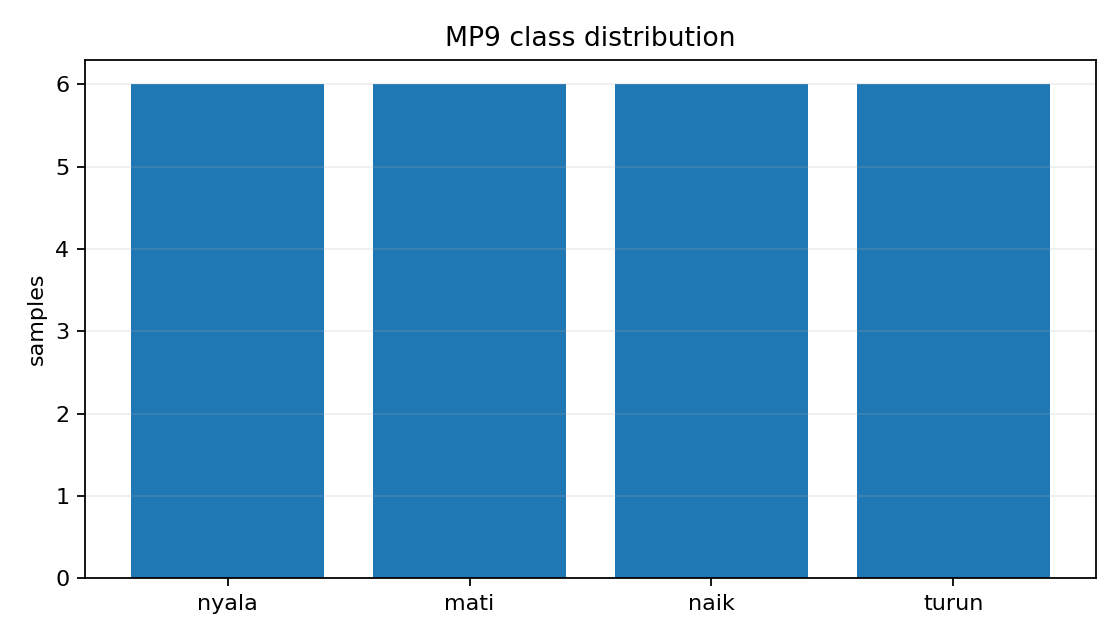

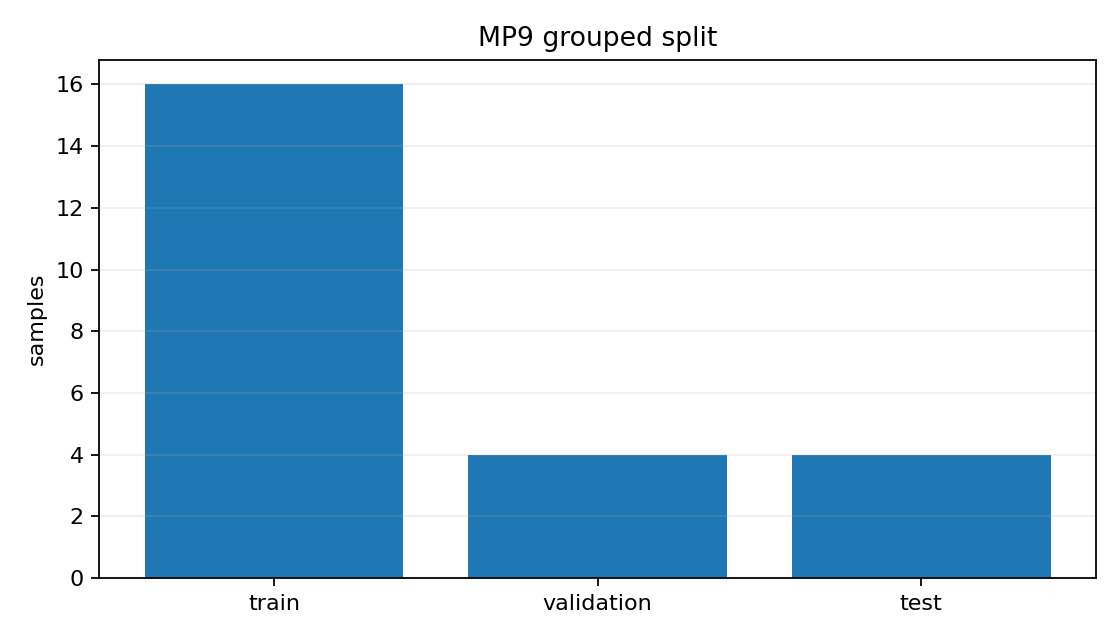

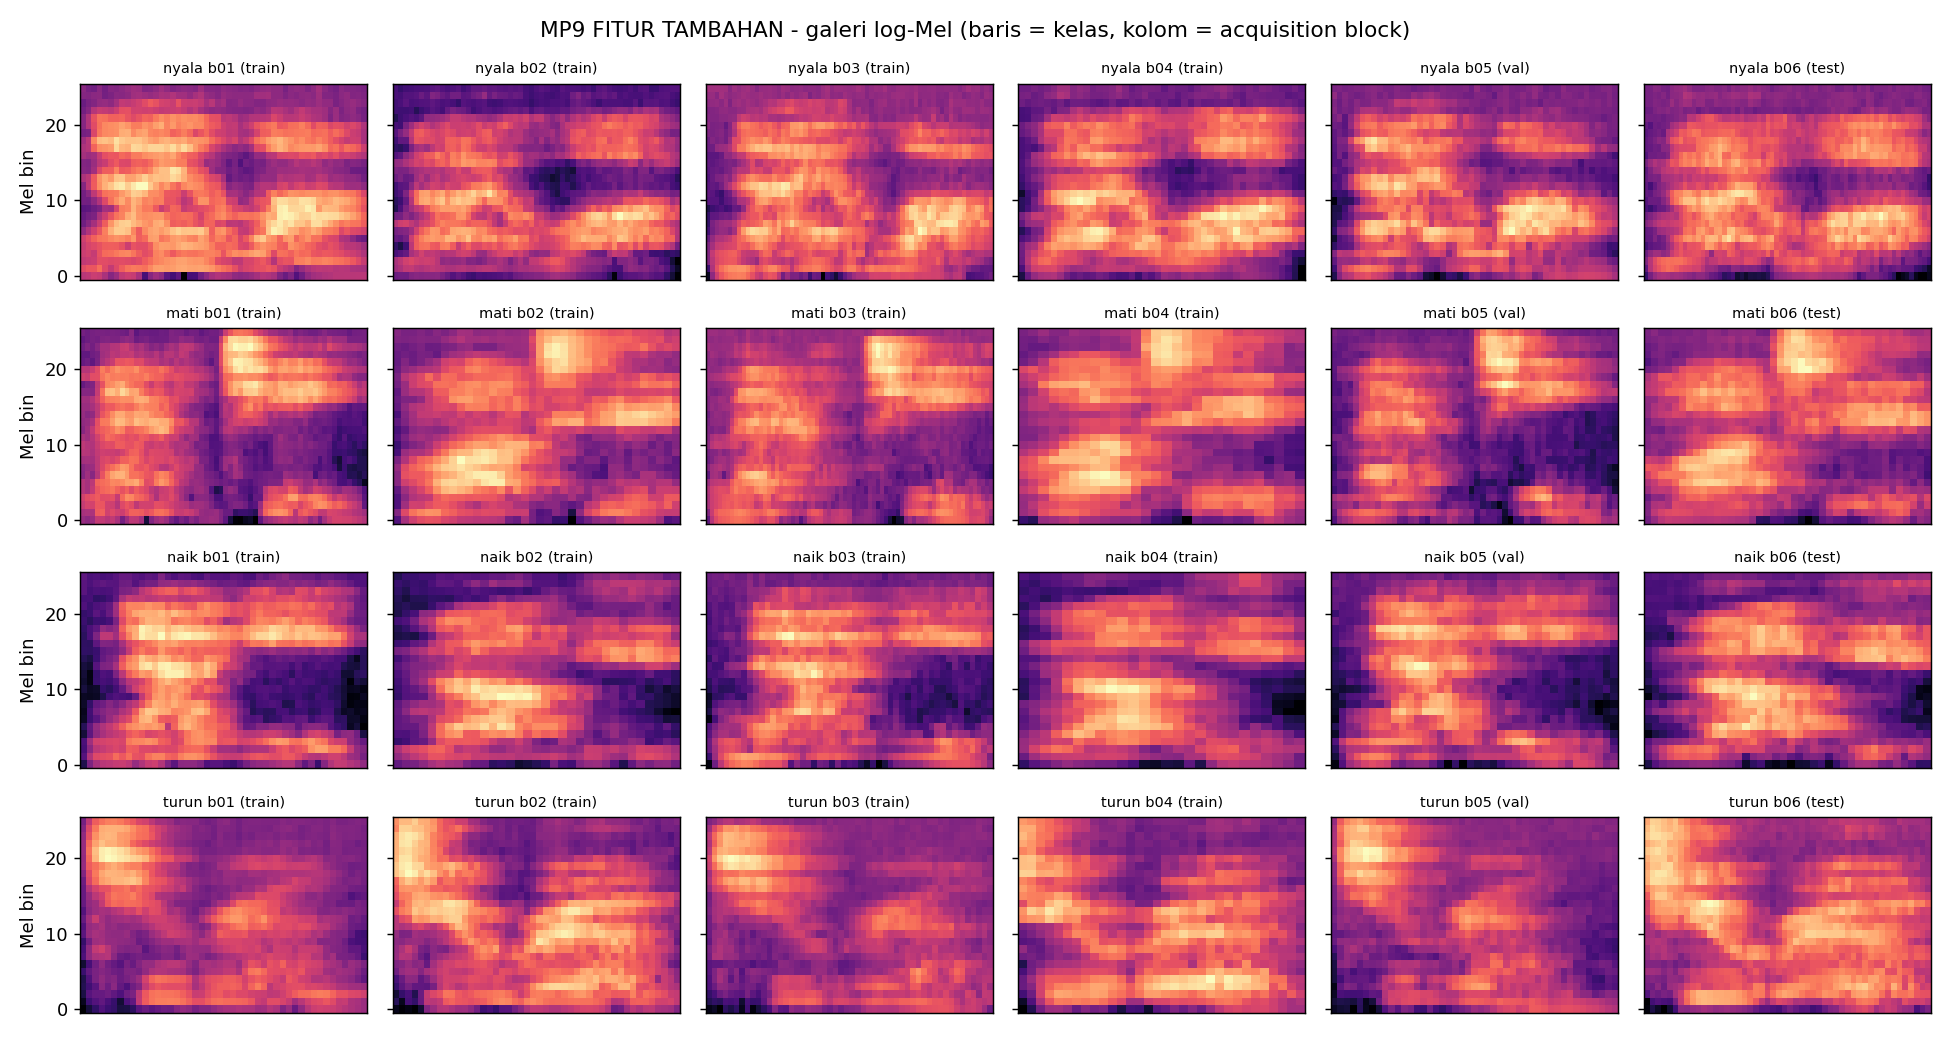

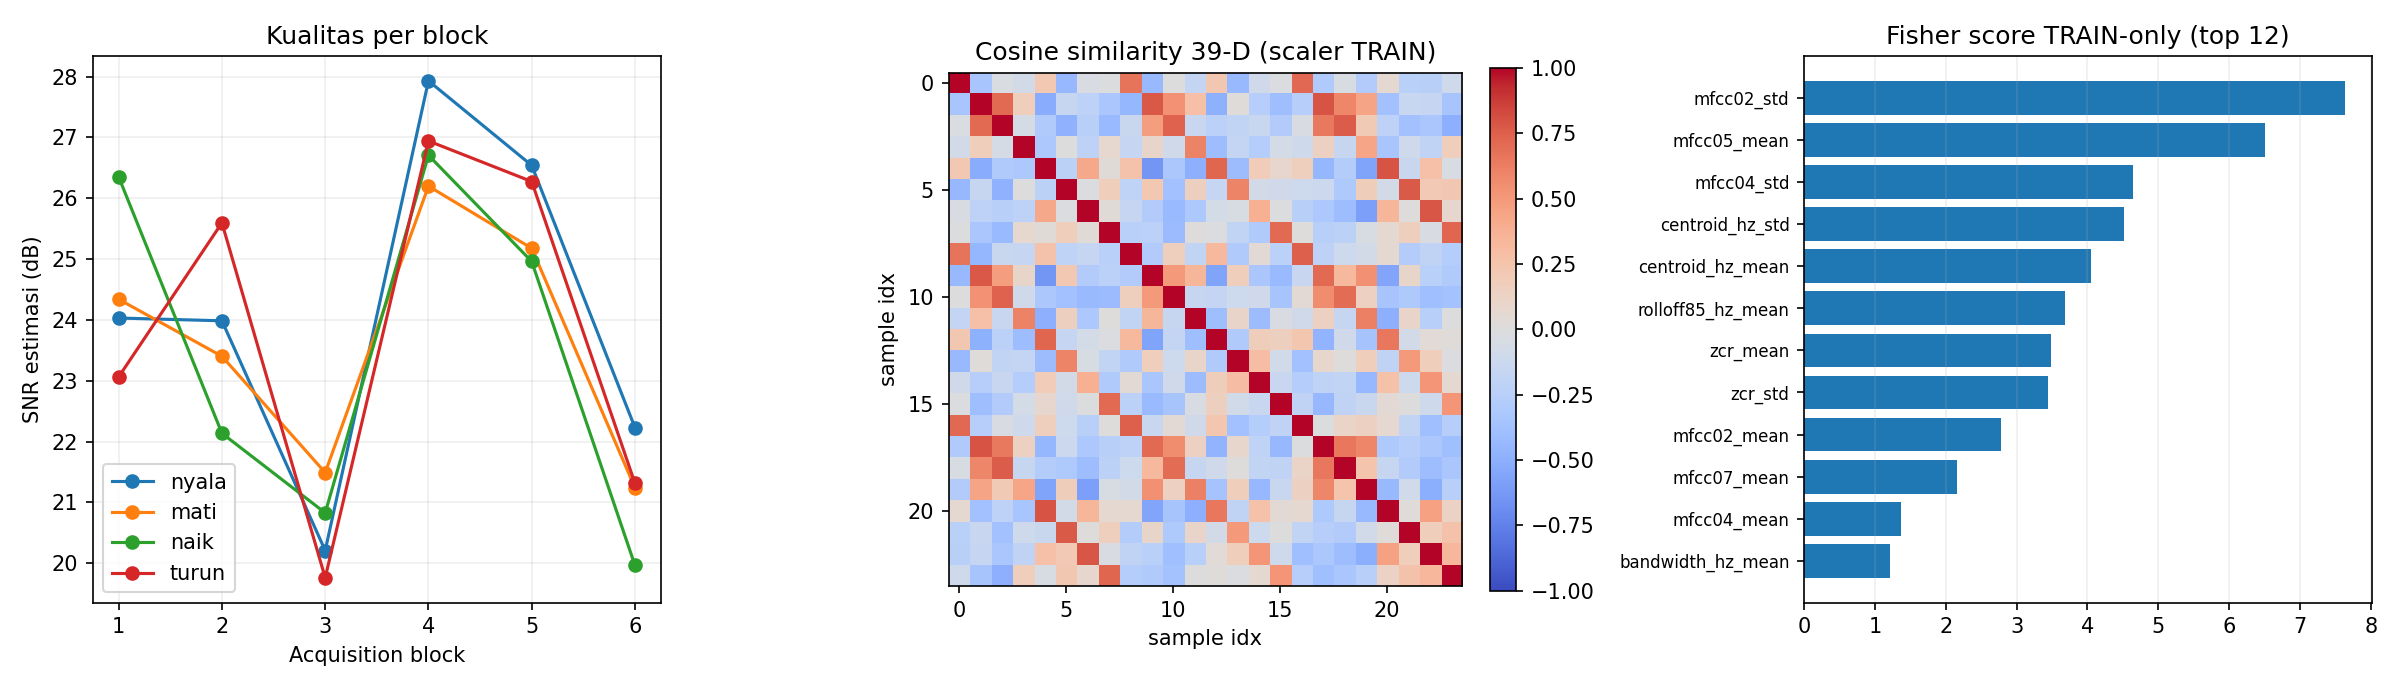

In [18]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp09_class_distribution.png', 'mp09_split_distribution.png', 'mp09_extension_logmel_gallery.png', 'mp09_extension_dataset_audit.png']:
        display(Image(filename=str(OUT_FIG/p), width=820))